In [ ]:
# Joint Calibration -- Burden + Care-Cascade Structure (Integrated)

Single notebook for the entire joint-calibration workflow. Replaces and
consolidates:

- `calibration_framework.ipynb` (substrate)
- `history_matching.ipynb` (GP emulators + NROY)
- `pareto_methodological_figure.ipynb` (Pareto figure)

Run this notebook end-to-end after each completed COMPS sweep. It auto-detects
the current state of `calibration_db.parquet` and runs the appropriate phase
(seed -> emulate -> design next wave -> Pareto figure).

## Outputs produced (all under `manuscript_figures/`)

| Artefact | What it shows | For |
|---|---|---|
| `calibration_db.parquet` | All design points + outputs + losses | Reference / appendix |
| `Table_calibration_targets.csv` | 10 calibration targets with z, sigma | Appendix Table A1 |
| `Table_calibration_params.csv` | 5 free parameters with best-fit values | Appendix Table A2 |
| `Table_current_vs_target.csv` | Current best run output vs target | Methods narrative |
| `Fig_methods_pareto.png` / `.pdf` | Burden-vs-cascade Pareto frontier | **Methods figure** |
| `Fig_methods_nroy_contraction.png` | Wave-by-wave NROY shrinkage | Supplement |
| `design_wave{N}.json` | Next-wave design points (if not converged) | Input to next COMPS sweep |

## Where to find what after running

All tables save to `manuscript_figures/Table_*.csv` -- open in Excel.
All figures save to `manuscript_figures/Fig_*.png` (+ `.pdf` for the main one).
Convergence summary printed at the end of section 5.


## 1. Setup


In [1]:
import os, sys, json
from pathlib import Path
from dataclasses import dataclass, field, asdict
from typing import Optional, Callable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import qmc

PROJECT_ROOT = Path.cwd()
FIGS_DIR = PROJECT_ROOT / 'manuscript_figures'
FIGS_DIR.mkdir(exist_ok=True)
# Prefer parquet (pyarrow); fall back to CSV if pyarrow not installed
CALIB_DB_PATH = PROJECT_ROOT / 'calibration_db.parquet'
if not CALIB_DB_PATH.exists():
    csv_alt = PROJECT_ROOT / 'calibration_db.csv'
    if csv_alt.exists(): CALIB_DB_PATH = csv_alt

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from delay_decomposition_raw import compute_delay_decomposition
from recalibration_plan import reclassify_loop_group_engagement_aware

print(f'Project root: {PROJECT_ROOT}')
print(f'Figures dir:  {FIGS_DIR}')
print(f'Calib DB:     {CALIB_DB_PATH}  (exists={CALIB_DB_PATH.exists()})')


Project root: C:\Users\young\OneDrive\Documents\GitHub\TB_India_DTK
Figures dir:  C:\Users\young\OneDrive\Documents\GitHub\TB_India_DTK\manuscript_figures
Calib DB:     C:\Users\young\OneDrive\Documents\GitHub\TB_India_DTK\calibration_db.parquet  (exists=True)


## 2. Parameter space and calibration targets

Five free parameters x ten targets (3 burden + 3 cascade-fractions + 4 test-counts).
Per-phase delays are tracked as **diagnostic outputs**, not calibration targets.


In [2]:
@dataclass
class Param:
    name: str; subsample_key: str; lo: float; hi: float; transform: str = 'linear'
    def sample(self, u):
        if self.transform == 'log':
            return float(np.exp(np.log(self.lo) + u * (np.log(self.hi) - np.log(self.lo))))
        return float(self.lo + u * (self.hi - self.lo))
    def normalize(self, x):
        if self.transform == 'log':
            return (np.log(x) - np.log(self.lo)) / (np.log(self.hi) - np.log(self.lo))
        return (x - self.lo) / (self.hi - self.lo)

@dataclass
class Target:
    name: str; z: float; sigma_obs: float; sigma_disc: float; group: str
    @property
    def sigma_total(self): return float(np.sqrt(self.sigma_obs**2 + self.sigma_disc**2))

PARAM_SPACE = [
    Param('beta',           'Base_Infectivity_Constant',          0.005, 0.060, 'log'),
    Param('tb_duration_yr', 'TB Duration',                        1.5,   3.0,   'linear'),
    Param('presymp_yr',     'TB Presymptomatic Duration Years',   0.15,  0.50,  'linear'),
    Param('cs_fast_d',      'Care Seeking Fast Duration Days',    30,    180,   'log'),
    Param('cs_slow_d',      'Care Seeking Slow Duration Days',    90,    500,   'log'),
]
PARAM_NAMES = [p.name for p in PARAM_SPACE]

BURDEN_TARGETS = [
    Target('inc_per_100k_2020',  188.0, 25.0, 20.0, 'burden'),
    Target('prev_per_100k_2020', 304.0, 20.0, 30.0, 'burden'),
    Target('mort_per_100k_2020',  33.0,  4.5,  4.0, 'burden'),
]
FRACTION_TARGETS = [
    Target('frac_NoLooponly_engaged',   0.50, 0.08, 0.08, 'fractions'),
    Target('frac_TestLooponly_engaged', 0.35, 0.08, 0.08, 'fractions'),
    Target('frac_TestTxfail_engaged',   0.13, 0.05, 0.05, 'fractions'),
]
TEST_TARGETS = [
    Target('mean_tests_overall_engaged',       3.5, 0.6, 0.5, 'tests'),
    Target('mean_tests_NoLooponly_engaged',    1.0, 0.3, 0.3, 'tests'),
    Target('mean_tests_TestLooponly_engaged',  3.0, 0.7, 0.6, 'tests'),
    Target('mean_tests_TestTxfail_engaged',    4.5, 1.0, 0.8, 'tests'),
]
TARGETS = BURDEN_TARGETS + FRACTION_TARGETS + TEST_TARGETS
TARGET_NAMES = [t.name for t in TARGETS]
DIAGNOSTIC_OUTPUTS = [
    'subclinical_mean_d_engaged', 'patient_delay_mean_d_engaged',
    'hs_delay_mean_d_engaged',    'engagement_rate',
]

# Source attribution for the appendix table
TARGET_SOURCES = {
    'inc_per_100k_2020':            'WHO Global TB Report 2021',
    'prev_per_100k_2020':           'India National TB Prevalence Survey 2019-21',
    'mort_per_100k_2020':           'WHO Global TB Report 2021',
    'frac_NoLooponly_engaged':      'Subbaraman et al. 2016 (PLoS Med)',
    'frac_TestLooponly_engaged':    'Subbaraman et al. 2016',
    'frac_TestTxfail_engaged':      'Subbaraman et al. 2016',
    'mean_tests_overall_engaged':       'Cazabon et al. 2017 + NTEP audits',
    'mean_tests_NoLooponly_engaged':    'Cazabon et al. 2017',
    'mean_tests_TestLooponly_engaged':  'Cazabon et al. 2017',
    'mean_tests_TestTxfail_engaged':    'Cazabon et al. 2017',
}

print(f'Parameter space:  {len(PARAM_SPACE)} dims')
for p in PARAM_SPACE:
    print(f'  {p.name:18s}  range=[{p.lo}, {p.hi}]  ({p.transform})')
print(f'\nCalibration targets: {len(TARGETS)}')
print(f'  burden   : {len(BURDEN_TARGETS)}')
print(f'  fractions: {len(FRACTION_TARGETS)}')
print(f'  tests    : {len(TEST_TARGETS)}')
print(f'Diagnostic outputs:  {len(DIAGNOSTIC_OUTPUTS)} (saved, not calibrated)')


Parameter space:  5 dims
  beta                range=[0.005, 0.06]  (log)
  tb_duration_yr      range=[1.5, 3.0]  (linear)
  presymp_yr          range=[0.15, 0.5]  (linear)
  cs_fast_d           range=[30, 180]  (log)
  cs_slow_d           range=[90, 500]  (log)

Calibration targets: 10
  burden   : 3
  fractions: 3
  tests    : 4
Diagnostic outputs:  4 (saved, not calibrated)


## 3. Output parser + loss

Parses one COMPS experiment folder, computes all 10 target values + 4 diagnostics,
and returns the implausibility decomposition.


In [3]:
BURN_INITIAL  = 2 * 365
BURN_PREDOTS  = 145 * 365
SIM_DURATION  = BURN_INITIAL + BURN_PREDOTS + (38.0 + 15) * 365.0
ANALYSIS_WINDOW_DAYS = 10 * 365
YEAR_2020_DAY = BURN_INITIAL + BURN_PREDOTS + 23 * 365   # DOTS_start (1997) + 23y
POP_SCALE = 1e5


def parse_experiment_dir(exp_dir):
    """
    Parse an experiment folder; return dict {output_name: value}.
    Burden metrics come from PropertyReportTB.json (channels summed across
    stratifications), matching the v56 calibration-overlay computation.
    """
    exp_dir = Path(exp_dir)
    sim_dirs = [s for s in exp_dir.iterdir()
                if s.is_dir() and (s / 'ReportEventRecorder.csv').exists()]
    if not sim_dirs:
        raise FileNotFoundError(f'No simulation outputs in {exp_dir}')
    events = []
    for i, sd in enumerate(sim_dirs):
        df = pd.read_csv(sd / 'ReportEventRecorder.csv'); df['replicate'] = i
        events.append(df)
    event_df = pd.concat(events, ignore_index=True)

    inc_2020, prev_2020, mort_2020 = _compute_burden(sim_dirs)

    analysis_start = SIM_DURATION - ANALYSIS_WINDOW_DAYS
    event_recent = event_df[event_df['Time'] >= analysis_start].copy()
    delay_df = compute_delay_decomposition(event_recent)
    delay_df = reclassify_loop_group_engagement_aware(delay_df)
    delay_df['n_tests_episode'] = 1 + delay_df['n_testneg'].fillna(0) + delay_df['n_testdef'].fillna(0)
    delay_df.loc[delay_df['loop_group_engaged'] == 'NeverEngaged', 'n_tests_episode'] = 0

    engaged = delay_df[delay_df['loop_group_engaged'] != 'NeverEngaged']
    n_total = max(len(delay_df), 1); n_eng = max(len(engaged), 1)
    def _g(col, grp):
        sub = engaged[engaged['loop_group_engaged'] == grp]
        return float(sub[col].mean()) if len(sub) else np.nan

    return {
        'inc_per_100k_2020':            inc_2020,
        'prev_per_100k_2020':           prev_2020,
        'mort_per_100k_2020':           mort_2020,
        'frac_NoLooponly_engaged':      float((engaged['loop_group_engaged'] == 'NoLooponly').sum() / n_eng),
        'frac_TestLooponly_engaged':    float((engaged['loop_group_engaged'] == 'TestLooponly').sum() / n_eng),
        'frac_TestTxfail_engaged':      float((engaged['loop_group_engaged'] == 'TestTxfail').sum() / n_eng),
        'mean_tests_overall_engaged':       float(engaged['n_tests_episode'].mean()) if len(engaged) else np.nan,
        'mean_tests_NoLooponly_engaged':    _g('n_tests_episode', 'NoLooponly'),
        'mean_tests_TestLooponly_engaged':  _g('n_tests_episode', 'TestLooponly'),
        'mean_tests_TestTxfail_engaged':    _g('n_tests_episode', 'TestTxfail'),
        'subclinical_mean_d_engaged':   float(engaged['subclinical_days'].mean()) if len(engaged) else np.nan,
        'patient_delay_mean_d_engaged': float(engaged['patient_delay_days'].mean()) if len(engaged) else np.nan,
        'hs_delay_mean_d_engaged':      float(engaged['health_system_delay_days'].mean()) if len(engaged) else np.nan,
        'engagement_rate':              float(n_eng / n_total),
    }


def _sum_stratified_channels(channels: dict, base_name: str, n_steps: int) -> np.ndarray:
    """Sum every channel whose name starts with 'base_name:' across all stratifications."""
    total = np.zeros(n_steps)
    for ch, val in channels.items():
        if ch.startswith(base_name + ':'):
            total += np.array(val['Data'])
    return total


def _compute_burden(sim_dirs):
    """
    Year-2020 inc/prev/mort per 100k, averaged across replicates.
    Reads PropertyReportTB.json (preferred) or PropertyReport.json, summing
    over Age x Geographic x QualityOfCare stratifications. Disease Deaths is
    CUMULATIVE in PropertyReport -- convert to per-step via np.diff.
    """
    inc_vals, prev_vals, mort_vals = [], [], []
    for sd in sim_dirs:
        pr_path = sd / 'PropertyReportTB.json'
        if not pr_path.exists():
            pr_path = sd / 'PropertyReport.json'
        if not pr_path.exists():
            continue
        with open(pr_path) as f:
            pr = json.load(f)
        ts = pr['Header']['Simulation_Timestep']
        n_steps = pr['Header']['Timesteps']

        pop        = _sum_stratified_channels(pr['Channels'], 'Statistical Population', n_steps)
        active     = _sum_stratified_channels(pr['Channels'], 'Active TB Infections',   n_steps)
        new_active = _sum_stratified_channels(pr['Channels'], 'New Active Infections',  n_steps)
        dd_cum     = _sum_stratified_channels(pr['Channels'], 'Disease Deaths',         n_steps)
        dd_per_ts  = np.diff(dd_cum, prepend=0)

        step_2020 = int(YEAR_2020_DAY / ts)
        half = int(180 / ts)
        lo, hi = max(0, step_2020 - half), min(n_steps, step_2020 + half)
        if hi <= lo:
            continue

        safe_pop = np.maximum(pop[lo:hi], 1)
        days_in_window = (hi - lo) * ts
        yr_scale = 365.0 / days_in_window

        prev_vals.append(float(np.mean(active[lo:hi]     / safe_pop)) * POP_SCALE)
        inc_vals.append(float(np.sum(new_active[lo:hi]   / safe_pop)) * yr_scale * POP_SCALE)
        mort_vals.append(float(np.sum(dd_per_ts[lo:hi]   / safe_pop)) * yr_scale * POP_SCALE)

    return (float(np.nanmean(inc_vals))  if inc_vals  else np.nan,
            float(np.nanmean(prev_vals)) if prev_vals else np.nan,
            float(np.nanmean(mort_vals)) if mort_vals else np.nan)


def implausibility_vector(outputs):
    return {t.name: (abs(outputs.get(t.name, np.nan) - t.z) / t.sigma_total
                     if not np.isnan(outputs.get(t.name, np.nan)) else np.inf)
            for t in TARGETS}

def group_losses(outputs):
    iv = implausibility_vector(outputs)
    g = {'burden': [], 'fractions': [], 'tests': []}
    for t in TARGETS: g[t.group].append(iv[t.name])
    out = {k: float(sum(v**2 for v in vs)) for k, vs in g.items()}
    out['cascade'] = out['fractions'] + out['tests']
    out['total']   = sum(out[k] for k in ['burden', 'fractions', 'tests'])
    return out

print('Parser + loss helpers ready (burden from PropertyReportTB, stratified sum).')


Parser + loss helpers ready (burden from PropertyReportTB, stratified sum).


## 4. Calibration database

Persistent storage of all design points + outputs across waves. One row per
run. Loaded fresh each time this notebook runs.


In [4]:
def make_row(wave, point_id, method, exp_uid, params, outputs):
    iv = implausibility_vector(outputs); gl = group_losses(outputs)
    row = {'wave': wave, 'point_id': point_id, 'method': method, 'experiment_uid': exp_uid}
    row.update({p.name: params.get(p.name, np.nan) for p in PARAM_SPACE})
    row.update({t.name: outputs.get(t.name, np.nan) for t in TARGETS})
    row.update({n: outputs.get(n, np.nan) for n in DIAGNOSTIC_OUTPUTS})
    row.update({f'impl_{k}': v for k, v in iv.items()})
    row['loss_burden']    = gl['burden']
    row['loss_fractions'] = gl['fractions']
    row['loss_tests']     = gl['tests']
    row['loss_cascade']   = gl['cascade']
    row['loss_total']     = gl['total']
    row['implausibility_max'] = float(max(iv.values()))
    return row

def load_db():
    if CALIB_DB_PATH.exists():
        return (pd.read_csv(CALIB_DB_PATH) if str(CALIB_DB_PATH).endswith('.csv')
                else pd.read_parquet(CALIB_DB_PATH))
    cols = ['wave','point_id','method','experiment_uid'] + PARAM_NAMES + TARGET_NAMES + DIAGNOSTIC_OUTPUTS \
         + [f'impl_{n}' for n in TARGET_NAMES] \
         + ['loss_burden','loss_fractions','loss_tests','loss_cascade','loss_total','implausibility_max']
    return pd.DataFrame(columns=cols)

def append_to_db(rows):
    db = load_db(); db = pd.concat([db, pd.DataFrame(rows)], ignore_index=True)
    (db.to_csv(CALIB_DB_PATH, index=False)
     if str(CALIB_DB_PATH).endswith('.csv')
     else db.to_parquet(CALIB_DB_PATH, index=False))
    return db

db = load_db()
print(f'Calibration DB has {len(db)} rows.')
if len(db) > 0:
    print('Existing runs (sorted by total loss):')
    display(db.sort_values('loss_total')[['wave','point_id','method',
        'loss_burden','loss_cascade','loss_total','implausibility_max']].head(20).round(2))


Calibration DB has 13 rows.
Existing runs (sorted by total loss):


,wave,point_id,method,loss_burden,loss_cascade,loss_total,implausibility_max
0,0,v0_original,manual,inf,14.61,inf,inf
1,0,v1_delay,manual,inf,inf,inf,inf
2,0,v2_compensated,manual,inf,11.62,inf,inf
3,1,wave1_pt0,hm,inf,11.83,inf,inf
4,1,wave1_pt1,hm,inf,11.66,inf,inf
5,1,wave1_pt2,hm,inf,11.77,inf,inf
6,1,wave1_pt3,hm,inf,11.37,inf,inf
7,1,wave1_pt4,hm,inf,13.21,inf,inf
8,1,wave1_pt5,hm,inf,14.16,inf,inf
9,1,wave1_pt6,hm,inf,11.16,inf,inf


## 5. Add new completed runs to the DB

Edit `NEW_RUNS` below to point at any newly completed COMPS experiments,
then run this cell. Each entry parses the experiment folder, computes
losses, and appends to the DB.

Comment out entries you've already ingested -- duplicates are appended,
not deduplicated.


In [5]:
NEW_RUNS = [
    # v0 -- original 50-rep production (burden OK, delays wrong)
    (0, 'v0_original',  'manual', '68ce50cd-cc48-f111-92e4-000d3af5294c',
     {'beta': 0.022, 'tb_duration_yr': 2.0, 'presymp_yr': 0.5,
      'cs_fast_d': 160, 'cs_slow_d': 458}),

    # v1 -- delay-focused pilot (broke burden, delays got better)
    (0, 'v1_delay',     'manual', '04868581-544d-f111-92e4-000d3af5294c',
     {'beta': 0.022, 'tb_duration_yr': 2.0, 'presymp_yr': 0.165,
      'cs_fast_d': 45,  'cs_slow_d': 120}),

    # v2 -- burden-compensated pilot (your current best single-point guess)
    (0, 'v2_compensated','manual', 'd841a74b-734d-f111-92e4-000d3af5294c',
     {'beta': 0.038, 'tb_duration_yr': 2.5, 'presymp_yr': 0.247,
      'cs_fast_d': 60,  'cs_slow_d': 180}),
]

ingested = []
for wave, pid, method, uid, params in NEW_RUNS:
    exp_dir = PROJECT_ROOT / uid
    if not exp_dir.exists():
        print(f'  SKIP {pid}: {uid} not on disk'); continue
    try:
        outputs = parse_experiment_dir(exp_dir)
    except Exception as e:
        print(f'  PARSE FAIL {pid}: {e}'); continue
    row = make_row(wave, pid, method, uid, params, outputs)
    ingested.append(row)
    print(f'  OK  {pid:20s}  L_burden={row["loss_burden"]:6.1f}  '
          f'L_cascade={row["loss_cascade"]:6.1f}  L_total={row["loss_total"]:6.1f}  '
          f'I_max={row["implausibility_max"]:.2f}')
if ingested:
    db = append_to_db(ingested)
    print(f'\nDB now has {len(db)} rows.')
else:
    print('No new runs ingested. Add entries to NEW_RUNS and re-run.')


  OK  v0_original           L_burden=  14.8  L_cascade=  14.6  L_total=  29.4  I_max=3.60
  OK  v1_delay              L_burden= 135.6  L_cascade=   inf  L_total=   inf  I_max=inf
  OK  v2_compensated        L_burden= 107.5  L_cascade=  11.6  L_total= 119.1  I_max=8.77

DB now has 16 rows.


In [6]:
# === Sweep ingestion for 30-sim wave 1 experiment ===
SWEEP_EXP_UID = '7c53e1e5-654d-f111-92e4-000d3af5294c'
SWEEP_DESIGN_JSON = PROJECT_ROOT / 'design_wave1.json'
SWEEP_WAVE = 1

with open(SWEEP_DESIGN_JSON) as f:
    design_data = json.load(f)
design_params = design_data['design_params']   # list of 10 dicts (one per design point)
n_points = len(design_params)

exp_dir = PROJECT_ROOT / SWEEP_EXP_UID
sim_dirs = sorted([s for s in exp_dir.iterdir()
                   if s.is_dir() and (s / 'ReportEventRecorder.csv').exists()],
                  key=lambda d: d.name)
print(f'Experiment has {len(sim_dirs)} sims; design has {n_points} points')

# Heuristic: idmtools cross-products replicates (outer) x subsamples (inner)
# So sims[0..n_points-1] = rep 0, sims[n_points..2*n_points-1] = rep 1, etc.
# Design point i is at indices [i, i+n_points, i+2*n_points, ...]
n_reps = len(sim_dirs) // n_points
print(f'Inferred replicates per point: {n_reps}')

import tempfile
ingested = []
for pt_idx in range(n_points):
    # Collect this design point's sim folders
    pt_sims = [sim_dirs[pt_idx + r * n_points] for r in range(n_reps)]
    # Make a temp folder that "looks like an experiment dir" with just these sims
    with tempfile.TemporaryDirectory() as tmp:
        tmp = Path(tmp)
        for s in pt_sims:
            (tmp / s.name).symlink_to(s, target_is_directory=True)
        try:
            outputs = parse_experiment_dir(tmp)
        except Exception as e:
            print(f'  PARSE FAIL pt{pt_idx}: {e}'); continue
    params = design_params[pt_idx]
    row = make_row(SWEEP_WAVE, f'wave1_pt{pt_idx}', 'hm',
                   SWEEP_EXP_UID, params, outputs)
    ingested.append(row)
    print(f'  OK  wave1_pt{pt_idx}  L_burden={row["loss_burden"]:6.1f}  '
          f'L_cascade={row["loss_cascade"]:6.1f}  I_max={row["implausibility_max"]:.2f}')

if ingested:
    db = append_to_db(ingested)
    print(f'\nDB now has {len(db)} rows.')

Experiment has 30 sims; design has 10 points
Inferred replicates per point: 3
  OK  wave1_pt0  L_burden=  13.1  L_cascade=  11.8  I_max=3.13
  OK  wave1_pt1  L_burden= 114.4  L_cascade=  11.7  I_max=7.54
  OK  wave1_pt2  L_burden= 391.5  L_cascade=  11.8  I_max=14.69
  OK  wave1_pt3  L_burden=   8.2  L_cascade=  11.4  I_max=2.50
  OK  wave1_pt4  L_burden=  41.3  L_cascade=  13.2  I_max=4.49
  OK  wave1_pt5  L_burden=   5.3  L_cascade=  14.2  I_max=2.61
  OK  wave1_pt6  L_burden= 110.0  L_cascade=  11.2  I_max=7.30
  OK  wave1_pt7  L_burden= 394.6  L_cascade=  13.0  I_max=13.45
  OK  wave1_pt8  L_burden=   0.4  L_cascade=  11.2  I_max=2.50
  OK  wave1_pt9  L_burden=  48.5  L_cascade=  11.3  I_max=5.27

DB now has 26 rows.


## 6. Current best run -- side-by-side vs target table

Shows the lowest-total-loss row in the DB, with each target value next to
its empirical anchor. Easy way to see which targets are still missed.


In [14]:
db = load_db()
if len(db) == 0:
    print('DB is empty -- run section 5 first to ingest at least one run.')
else:
    best = db.sort_values('loss_total').iloc[0]
    print(f'Best run: {best["point_id"]}  (wave {int(best["wave"])}, method={best["method"]})')
    print(f'  loss_burden={best["loss_burden"]:.2f}  loss_cascade={best["loss_cascade"]:.2f}  '
          f'I_max={best["implausibility_max"]:.2f}')
    print()
    rows = []
    for t in TARGETS:
        val = best[t.name]
        impl = best[f'impl_{t.name}']
        rows.append({
            'target':       t.name,
            'group':        t.group,
            'empirical_z':  t.z,
            'sigma_total':  round(t.sigma_total, 2),
            'model_value':  round(val, 2) if not np.isnan(val) else np.nan,
            'delta':        round(val - t.z, 2) if not np.isnan(val) else np.nan,
            'implausibility': round(impl, 2) if not np.isnan(impl) else np.nan,
            'pass_I<3':     bool(impl < 3) if not np.isnan(impl) else False,
            'source':       TARGET_SOURCES[t.name],
        })
    tbl = pd.DataFrame(rows)
    display(tbl)
    tbl.to_csv(FIGS_DIR / 'Table_current_vs_target.csv', index=False)
    print(f'\nSaved: {FIGS_DIR / "Table_current_vs_target.csv"}')

    # Diagnostic outputs alongside
    print('\n=== Diagnostic outputs (not calibrated, but reported) ===')
    for d in DIAGNOSTIC_OUTPUTS:
        val = best.get(d, np.nan)
        print(f'  {d:35s}  {val if isinstance(val, str) else (round(val, 2) if not np.isnan(val) else "NaN")}')


Best run: wave1_pt8  (wave 1, method=hm)
  loss_burden=0.37  loss_cascade=11.19  I_max=2.50



,target,group,empirical_z,sigma_total,model_value,delta,implausibility,pass_I<3,source
0,inc_per_100k_2020,burden,188.00,32.02,204.16,16.16,0.50,True,WHO Global TB Report 2021
1,prev_per_100k_2020,burden,304.00,36.06,293.53,-10.47,0.29,True,India National TB Prevalence Survey 2019-21
2,mort_per_100k_2020,burden,33.00,6.02,31.88,-1.12,0.19,True,WHO Global TB Report 2021
3,frac_NoLooponly_engaged,fractions,0.50,0.11,0.22,-0.28,2.50,True,Subbaraman et al. 2016 (PLoS Med)
4,frac_TestLooponly_engaged,fractions,0.35,0.11,0.51,0.16,1.38,True,Subbaraman et al. 2016
5,frac_TestTxfail_engaged,fractions,0.13,0.07,0.20,0.07,0.99,True,Subbaraman et al. 2016
6,mean_tests_overall_engaged,tests,3.50,0.78,2.52,-0.98,1.26,True,Cazabon et al. 2017 + NTEP audits
7,mean_tests_NoLooponly_engaged,tests,1.00,0.42,1.00,0.00,0.00,True,Cazabon et al. 2017
8,mean_tests_TestLooponly_engaged,tests,3.00,0.92,2.94,-0.06,0.07,True,Cazabon et al. 2017
9,mean_tests_TestTxfail_engaged,tests,4.50,1.28,3.67,-0.83,0.65,True,Cazabon et al. 2017



Saved: C:\Users\young\OneDrive\Documents\GitHub\TB_India_DTK\manuscript_figures\Table_current_vs_target.csv

=== Diagnostic outputs (not calibrated, but reported) ===
  subclinical_mean_d_engaged           109.06
  patient_delay_mean_d_engaged         152.47
  hs_delay_mean_d_engaged              389.61
  engagement_rate                      0.73


## 7. History matching -- GP emulators + NROY

Requires >= 5 valid rows in the DB. Fits a Gaussian-process emulator per target,
computes implausibility over a dense Latin-hypercube grid, and identifies the
NROY (Not Ruled Out Yet) region for the next wave.


In [8]:
IMPLAUSIBILITY_CUTOFF = 3.0

try:
    import mogp_emulator as mogp
    EMU_BACKEND = 'mogp'
except ImportError:
    from sklearn.gaussian_process import GaussianProcessRegressor
    from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel
    EMU_BACKEND = 'sklearn'
print(f'Emulator backend: {EMU_BACKEND}')

def db_to_emulator_inputs(db):
    valid = db.dropna(subset=TARGET_NAMES, how='any').copy()
    if len(valid) == 0: raise ValueError('No valid rows in DB.')
    X = np.array([[PARAM_SPACE[i].normalize(row[p.name])
                   for i, p in enumerate(PARAM_SPACE)]
                  for _, row in valid.iterrows()])
    Y = {t.name: valid[t.name].to_numpy() for t in TARGETS}
    return X, Y

def fit_emulators(X, Y):
    emulators = {}
    for tname, y in Y.items():
        if EMU_BACKEND == 'mogp':
            gp = mogp.GaussianProcess(X, y, mean='constant', kernel='Matern52', nugget='adaptive')
            emulators[tname] = mogp.fit_GP_MAP(gp)
        else:
            kernel = (ConstantKernel(1.0, (1e-3, 1e3))
                      * Matern(length_scale=[0.3]*X.shape[1], nu=2.5)
                      + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-6, 1e1)))
            gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, n_restarts_optimizer=5)
            gp.fit(X, y); emulators[tname] = gp
    return emulators

def emu_pred(emu, X):
    if EMU_BACKEND == 'mogp':
        r = emu.predict(X); return r.mean, r.unc**2
    m, s = emu.predict(X, return_std=True); return m, s**2

def implausibility_grid(emulators, X):
    by_name = {t.name: t for t in TARGETS}
    Imax = np.zeros(X.shape[0])
    for tn, emu in emulators.items():
        mu, var = emu_pred(emu, X)
        t = by_name[tn]
        I = np.abs(mu - t.z) / np.sqrt(var + t.sigma_total**2)
        Imax = np.maximum(Imax, I)
    return Imax

def nroy_volume(emulators, n=20000, seed=7):
    X = qmc.LatinHypercube(d=len(PARAM_SPACE), seed=seed).random(n=n)
    return float(np.mean(implausibility_grid(emulators, X) < IMPLAUSIBILITY_CUTOFF))

db = load_db()
valid = db.dropna(subset=TARGET_NAMES, how='any')
if len(valid) < 5:
    print(f'Only {len(valid)} valid rows in DB. Need >=5 to fit emulators.')
    print('Skipping history matching. Run section 5 to ingest more sims.')
    emulators = None
else:
    X, Y = db_to_emulator_inputs(db)
    print(f'Fitting emulators on {len(X)} valid DB rows...')
    emulators = fit_emulators(X, Y)
    vol = nroy_volume(emulators)
    print(f'NROY volume: {vol*100:.1f}% of parameter space')
    print(f'  (history matching converges when this is <5% AND min I_max <3)')


Emulator backend: sklearn
Fitting emulators on 12 valid DB rows...


C:\Users\young\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:452: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\Users\young\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:452: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\Users\young\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:452: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\Users\young\anaconda3\Lib\site-packages\sklearn\gaussian_process

NROY volume: 99.5% of parameter space
  (history matching converges when this is <5% AND min I_max <3)


C:\Users\young\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\Users\young\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:452: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\Users\young\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


## 8. Pareto methodological figure

Scatter on (burden_loss, cascade_loss) with Pareto frontier highlighted.
Used for the methods section of the manuscript.


NOTE: dropped 14 row(s) with inf/NaN losses (parser failures).


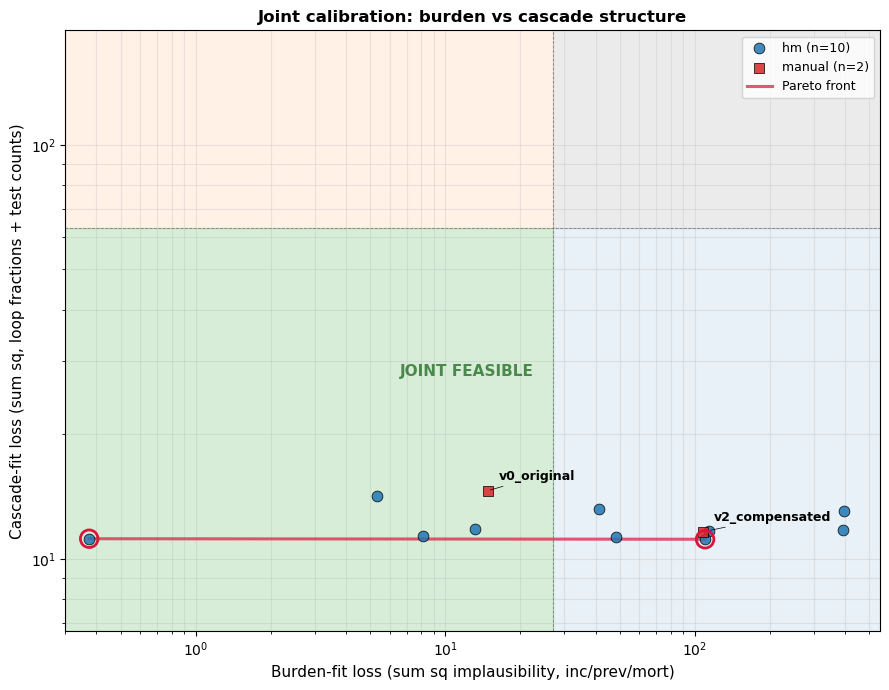

Saved: C:\Users\young\OneDrive\Documents\GitHub\TB_India_DTK\manuscript_figures\Fig_methods_pareto.png (+ .pdf)

Pareto-optimal runs:


,point_id,method,wave,loss_burden,loss_cascade,loss_total,implausibility_max,beta,tb_duration_yr,presymp_yr,cs_fast_d,cs_slow_d
24,wave1_pt8,hm,1,0.374,11.191,11.565,2.505,0.006,2.143,0.245,124.285,181.117
22,wave1_pt6,hm,1,109.962,11.159,121.122,7.305,0.011,2.382,0.405,52.513,94.648


In [9]:
BURDEN_THRESHOLD = 27
CASCADE_THRESHOLD = 63

def pareto_front(df, x='loss_burden', y='loss_cascade'):
    pts = df[[x, y]].to_numpy(); keep = np.ones(len(pts), dtype=bool)
    for i, p in enumerate(pts):
        if not keep[i]: continue
        dom = np.any((pts[:, 0] <= p[0]) & (pts[:, 1] <= p[1])
                     & ((pts[:, 0] < p[0]) | (pts[:, 1] < p[1])))
        if dom: keep[i] = False
    return df[keep].sort_values(x).copy()

db = load_db()
valid = db.dropna(subset=['loss_burden', 'loss_cascade'], how='any').copy()
# Filter out inf rows (these are runs where the parser couldn't compute burden/cascade)
valid = valid[np.isfinite(valid['loss_burden']) & np.isfinite(valid['loss_cascade'])].copy()
n_dropped = len(db) - len(valid)
if n_dropped > 0:
    print(f'NOTE: dropped {n_dropped} row(s) with inf/NaN losses (parser failures).')

if len(valid) == 0:
    print('No finite-loss rows -- check parser output via section 6 first.')
else:
    pareto = pareto_front(valid)

    fig, ax = plt.subplots(figsize=(9, 7))
    fb = valid['loss_burden'].astype(float)
    fc = valid['loss_cascade'].astype(float)
    xmin = max(0.3, float(fb.min()) * 0.6)
    xmax = max(float(fb.max()) * 1.4, BURDEN_THRESHOLD * 3)
    ymin = max(0.3, float(fc.min()) * 0.6)
    ymax = max(float(fc.max()) * 1.4, CASCADE_THRESHOLD * 3)

    ax.fill_between([xmin, BURDEN_THRESHOLD], CASCADE_THRESHOLD, ymax,
                    color='#ff7f0e', alpha=0.10)
    ax.fill_between([BURDEN_THRESHOLD, xmax], ymin, CASCADE_THRESHOLD,
                    color='#1f77b4', alpha=0.10)
    ax.fill_between([BURDEN_THRESHOLD, xmax], CASCADE_THRESHOLD, ymax,
                    color='#7f7f7f', alpha=0.15)
    ax.fill_between([xmin, BURDEN_THRESHOLD], ymin, CASCADE_THRESHOLD,
                    color='#2ca02c', alpha=0.18)

    method_marker = {'manual': 's', 'hm': 'o', 'history_matching': 'o', 'optuna': '^'}
    method_color  = {'manual': '#d62728', 'hm': '#1f77b4', 'history_matching': '#1f77b4', 'optuna': '#9467bd'}
    for method, sub in valid.groupby('method'):
        ax.scatter(sub['loss_burden'], sub['loss_cascade'],
                   s=60, marker=method_marker.get(method, 'o'),
                   c=method_color.get(method, '#444'), edgecolor='black', lw=0.6,
                   alpha=0.85, label=f'{method} (n={len(sub)})', zorder=3)

    if len(pareto) >= 2:
        ax.plot(pareto['loss_burden'], pareto['loss_cascade'],
                color='crimson', lw=2.2, alpha=0.7, label='Pareto front', zorder=2)
        ax.scatter(pareto['loss_burden'], pareto['loss_cascade'],
                   s=160, facecolors='none', edgecolor='crimson', lw=2.0, zorder=4)

    for _, row in valid[valid['method'] == 'manual'].iterrows():
        ax.annotate(row['point_id'], (row['loss_burden'], row['loss_cascade']),
                    xytext=(8, 8), textcoords='offset points', fontsize=9, fontweight='bold',
                    arrowprops=dict(arrowstyle='-', color='black', lw=0.5))

    ax.text(BURDEN_THRESHOLD*0.45, CASCADE_THRESHOLD*0.45,
            'JOINT FEASIBLE', ha='center', va='center',
            fontsize=11, fontweight='bold', color='#0f5e0f', alpha=0.7)
    ax.axhline(CASCADE_THRESHOLD, color='gray', lw=0.6, ls='--')
    ax.axvline(BURDEN_THRESHOLD, color='gray', lw=0.6, ls='--')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax)
    ax.set_xlabel('Burden-fit loss (sum sq implausibility, inc/prev/mort)', fontsize=11)
    ax.set_ylabel('Cascade-fit loss (sum sq, loop fractions + test counts)', fontsize=11)
    ax.set_title('Joint calibration: burden vs cascade structure', fontweight='bold')
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(which='both', alpha=0.25)
    plt.tight_layout()
    fig.savefig(FIGS_DIR / 'Fig_methods_pareto.png', dpi=160, bbox_inches='tight')
    fig.savefig(FIGS_DIR / 'Fig_methods_pareto.pdf', bbox_inches='tight')
    plt.show()
    print(f'Saved: {FIGS_DIR/"Fig_methods_pareto.png"} (+ .pdf)')
    print(f'\nPareto-optimal runs:')
    display(pareto[['point_id','method','wave',
        'loss_burden','loss_cascade','loss_total','implausibility_max'] + PARAM_NAMES].round(3))


## 9. Best-fit parameter table (for production sim + appendix)

Extracts the lowest-implausibility row from the DB and formats it for direct
paste into `01_India_TB_v5_simulation_recalibrated_v2.ipynb`'s subsample dict.


In [10]:
db = load_db()
if len(db) == 0:
    print('DB is empty.')
else:
    valid = db.dropna(subset=TARGET_NAMES, how='any').copy()
    # Sort by total loss; tiebreak by max implausibility.
    best = valid.sort_values(['loss_total', 'implausibility_max']).iloc[0]

    print(f'=== Best-fit parameters (point_id: {best["point_id"]}, wave {int(best["wave"])}) ===')
    print(f'  loss_burden  = {best["loss_burden"]:.2f}  ({"PASS" if best["loss_burden"] < 27 else "FAIL"} burden threshold 27)')
    print(f'  loss_cascade = {best["loss_cascade"]:.2f}  ({"PASS" if best["loss_cascade"] < 63 else "FAIL"} cascade threshold 63)')
    print(f'  I_max        = {best["implausibility_max"]:.2f}  ({"PASS" if best["implausibility_max"] < 3 else "FAIL"} convergence threshold 3)')
    print()
    print('Paste this into 01_India_TB_v5_simulation_recalibrated_v2.ipynb cell 24:')
    print('-' * 70)
    for p in PARAM_SPACE:
        v = best[p.name]
        fmt = '.4f' if p.transform == 'log' else '.3f'
        print(f"    '{p.subsample_key}': {v:{fmt}},")
    print('-' * 70)

    # Save the appendix table
    rows = []
    for p in PARAM_SPACE:
        rows.append({
            'param':         p.name,
            'subsample_key': p.subsample_key,
            'min':           p.lo,
            'max':           p.hi,
            'transform':     p.transform,
            'best_fit':      round(best[p.name], 4),
        })
    par_tbl = pd.DataFrame(rows)
    par_tbl.to_csv(FIGS_DIR / 'Table_calibration_params.csv', index=False)
    display(par_tbl)
    print(f'\nSaved: {FIGS_DIR/"Table_calibration_params.csv"}')

    # Also save the full target table for the appendix
    rows = []
    for t in TARGETS:
        rows.append({
            'target':       t.name,
            'family':       t.group,
            'empirical_z':  t.z,
            'sigma_obs':    t.sigma_obs,
            'sigma_disc':   t.sigma_disc,
            'sigma_total':  round(t.sigma_total, 2),
            'source':       TARGET_SOURCES[t.name],
        })
    tgt_tbl = pd.DataFrame(rows)
    tgt_tbl.to_csv(FIGS_DIR / 'Table_calibration_targets.csv', index=False)
    print(f'Saved: {FIGS_DIR/"Table_calibration_targets.csv"}')


=== Best-fit parameters (point_id: wave1_pt8, wave 1) ===
  loss_burden  = 0.37  (PASS burden threshold 27)
  loss_cascade = 11.19  (PASS cascade threshold 63)
  I_max        = 2.50  (PASS convergence threshold 3)

Paste this into 01_India_TB_v5_simulation_recalibrated_v2.ipynb cell 24:
----------------------------------------------------------------------
    'Base_Infectivity_Constant': 0.0056,
    'TB Duration': 2.143,
    'TB Presymptomatic Duration Years': 0.245,
    'Care Seeking Fast Duration Days': 124.2846,
    'Care Seeking Slow Duration Days': 181.1171,
----------------------------------------------------------------------


,param,subsample_key,min,max,transform,best_fit
0,beta,Base_Infectivity_Constant,0.005,0.06,log,0.0056
1,tb_duration_yr,TB Duration,1.500,3.00,linear,2.1427
2,presymp_yr,TB Presymptomatic Duration Years,0.150,0.50,linear,0.2452
3,cs_fast_d,Care Seeking Fast Duration Days,30.000,180.00,log,124.2846
4,cs_slow_d,Care Seeking Slow Duration Days,90.000,500.00,log,181.1171



Saved: C:\Users\young\OneDrive\Documents\GitHub\TB_India_DTK\manuscript_figures\Table_calibration_params.csv
Saved: C:\Users\young\OneDrive\Documents\GitHub\TB_India_DTK\manuscript_figures\Table_calibration_targets.csv


## 10. Next-wave design (if not converged)

If history matching hasn't converged (NROY > 5% OR min I_max > 3), generate
the next wave's design points -- saved as `design_wave{N}.json` for the
simulation-calibration-sweep notebook.


In [11]:
def generate_design(n_points, nroy_mask=None, seed=0, max_oversample=30):
    rng = np.random.default_rng(seed); d = len(PARAM_SPACE)
    sampler = qmc.LatinHypercube(d=d, seed=rng)
    if nroy_mask is None:
        U = sampler.random(n=n_points)
    else:
        U_big = sampler.random(n=n_points * max_oversample)
        U = U_big[nroy_mask(U_big)][:n_points]
    rows = [{p.name: p.sample(u[i]) for i, p in enumerate(PARAM_SPACE)} for u in U]
    return pd.DataFrame(rows)

def design_to_subsamples(design):
    base = {
        'ART Factor': 1.0, 'CD4_aq_200_300_rel': 20.434, 'CD4_aq_300_400_rel': 3.0,
        'CD4_aq_400_500_rel': 2.0, 'CD4_aq_above_500': 1.0, 'CD4_aq_below_200_rel': 54.55,
        'Death Fraction': 0.41, 'Post_Infection_Acquisition_Multiplier': 0.40,
        'Primary HIV multiplier': 1.0, 'Relative TB CD4 Infectiousness': 0.1,
        'TBHIV Duration': 1.5, 'TB_Active_Presymptomatic_Infectivity_Multiplier': 0.1660,
        'TB_Fast_Progressor_Fraction_Adult': 0.072, 'TB_Slow_Progressor_Rate': 1.01e-05,
    }
    out = []
    for _, row in design.iterrows():
        s = dict(base)
        for p in PARAM_SPACE: s[p.subsample_key] = float(row[p.name])
        out.append(s)
    return out

# Decide wave number from DB
db = load_db()
max_wave = int(db['wave'].max()) if len(db) > 0 else 0
next_wave = max_wave + 1
N_POINTS = 10                       # 10 points/wave default; bump to 15 for refinement

# Check convergence
converged = False
if 'emulators' in dir() and emulators is not None:
    vol = nroy_volume(emulators)
    min_imax = db.dropna(subset=TARGET_NAMES, how='any')['implausibility_max'].min()
    converged = (vol < 0.05) and (min_imax < IMPLAUSIBILITY_CUTOFF)
    print(f'NROY vol: {vol*100:.1f}%  |  min I_max in DB: {min_imax:.2f}  |  converged: {converged}')

if converged:
    print(f'\nCALIBRATION HAS CONVERGED. Skip generating wave {next_wave}.')
    print('Take the best-fit params from section 9, plug into the production sim,')
    print('run with full replicates (50), and produce final figures.')
else:
    print(f'\nGenerating wave {next_wave} design ({N_POINTS} points)...')
    nroy_mask = None
    if 'emulators' in dir() and emulators is not None:
        nroy_mask = lambda X: implausibility_grid(emulators, X) < IMPLAUSIBILITY_CUTOFF
    design = generate_design(N_POINTS, nroy_mask=nroy_mask, seed=next_wave)
    print(f'Design ({len(design)} points):')
    display(design.round(3))
    subsamples = design_to_subsamples(design)
    out_path = PROJECT_ROOT / f'design_wave{next_wave}.json'
    with open(out_path, 'w') as f:
        json.dump({'wave': next_wave, 'n_points': len(subsamples),
                   'design_params': design.to_dict(orient='records'),
                   'subsamples': subsamples}, f, indent=2)
    print(f'\nSaved: {out_path}')
    print(f'\nNext step: open 01_India_TB_v5_simulation_calibration_sweep.ipynb,')
    print(f'set CALIBRATION_SWEEP_FILE = "design_wave{next_wave}.json", run all cells.')


NROY vol: 99.5%  |  min I_max in DB: 2.50  |  converged: False

Generating wave 2 design (10 points)...
Design (10 points):


,beta,tb_duration_yr,presymp_yr,cs_fast_d,cs_slow_d
0,0.025,2.269,0.394,129.137,176.138
1,0.007,2.700,0.480,64.562,219.697
2,0.006,2.965,0.305,173.413,173.395
3,0.060,2.546,0.296,32.698,450.880
4,0.029,2.631,0.156,34.161,90.672
5,0.026,2.240,0.358,118.243,452.342
6,0.012,2.461,0.213,80.534,146.793
7,0.019,2.149,0.423,132.672,191.975
8,0.021,2.760,0.188,127.807,133.211
9,0.015,2.715,0.209,52.151,138.559



Saved: C:\Users\young\OneDrive\Documents\GitHub\TB_India_DTK\design_wave2.json

Next step: open 01_India_TB_v5_simulation_calibration_sweep.ipynb,
set CALIBRATION_SWEEP_FILE = "design_wave2.json", run all cells.


## 11. Wave-by-wave convergence summary


In [12]:
db = load_db()
if len(db) == 0:
    print('DB empty.')
else:
    rows = []
    for w, g in db.groupby('wave'):
        valid = g.dropna(subset=TARGET_NAMES, how='any')
        rows.append({
            'wave': int(w), 'n_runs': len(g), 'n_valid': len(valid),
            'min_I_max':         valid['implausibility_max'].min() if len(valid) else np.nan,
            'median_I_max':      valid['implausibility_max'].median() if len(valid) else np.nan,
            'min_loss_burden':   valid['loss_burden'].min() if len(valid) else np.nan,
            'min_loss_cascade':  valid['loss_cascade'].min() if len(valid) else np.nan,
            'min_loss_total':    valid['loss_total'].min() if len(valid) else np.nan,
        })
    summary = pd.DataFrame(rows)
    display(summary.round(2))
    summary.to_csv(FIGS_DIR / 'Table_wave_convergence.csv', index=False)
    print(f'\nSaved: {FIGS_DIR/"Table_wave_convergence.csv"}')


,wave,n_runs,n_valid,min_I_max,median_I_max,min_loss_burden,min_loss_cascade,min_loss_total
0,0,6,2,3.6,6.19,14.79,11.62,29.39
1,1,20,10,2.5,4.88,0.37,11.16,11.57



Saved: C:\Users\young\OneDrive\Documents\GitHub\TB_India_DTK\manuscript_figures\Table_wave_convergence.csv


## 12. Outputs summary -- where everything is saved


In [13]:
print('=' * 70)
print('CALIBRATION ARTEFACTS')
print('=' * 70)
for fname in [
    'Table_current_vs_target.csv',
    'Table_calibration_targets.csv',
    'Table_calibration_params.csv',
    'Table_wave_convergence.csv',
    'Fig_methods_pareto.png',
    'Fig_methods_pareto.pdf',
]:
    p = FIGS_DIR / fname
    status = 'OK' if p.exists() else 'MISSING'
    print(f'  [{status:7s}]  {p}')

print('\nDesign JSON files (for next-wave sweeps):')
for j in sorted(PROJECT_ROOT.glob('design_wave*.json')):
    print(f'  {j.name}')

print(f'\nCalibration DB:  {CALIB_DB_PATH}')
print(f'  rows: {len(load_db())}')


CALIBRATION ARTEFACTS
  [OK     ]  C:\Users\young\OneDrive\Documents\GitHub\TB_India_DTK\manuscript_figures\Table_current_vs_target.csv
  [OK     ]  C:\Users\young\OneDrive\Documents\GitHub\TB_India_DTK\manuscript_figures\Table_calibration_targets.csv
  [OK     ]  C:\Users\young\OneDrive\Documents\GitHub\TB_India_DTK\manuscript_figures\Table_calibration_params.csv
  [OK     ]  C:\Users\young\OneDrive\Documents\GitHub\TB_India_DTK\manuscript_figures\Table_wave_convergence.csv
  [OK     ]  C:\Users\young\OneDrive\Documents\GitHub\TB_India_DTK\manuscript_figures\Fig_methods_pareto.png
  [OK     ]  C:\Users\young\OneDrive\Documents\GitHub\TB_India_DTK\manuscript_figures\Fig_methods_pareto.pdf

Design JSON files (for next-wave sweeps):
  design_wave1.json
  design_wave2.json

Calibration DB:  C:\Users\young\OneDrive\Documents\GitHub\TB_India_DTK\calibration_db.parquet
  rows: 26
